# IndicSent-M — Final Tuned Training Notebook (Colab)

Trains and evaluates **Text-only (MuRIL)**, **Image-only (ViT)**, and **Multimodal Gated Fusion (MuRIL + ViT)** on the Memotion 3.0 Hinglish dataset.

**Upgrades applied for stronger F1 & reproducibility:**
- **UTF-8 Devanagari & Hinglish preservation:** Auto-detects tab vs. comma delimiters without `latin-1` fallback and preserves emojis as sentiment tokens.
- **Strict image matching & validation:** Matches strictly by ID/filename and verifies every image file with PIL (drops corrupt rows rather than feeding blank images).
- **Attention-masked mean pooling (Text) + Gated Multimodal Fusion:** Improves representation of noisy short OCR captions and models text–image incongruity (sarcasm).
- **No encoder freezing + cosine LR schedule:** Prevents wasted warmup steps and unfreeze shocks; uses per-mode differential LRs (`3e-5` MuRIL text, `2e-5` ViT/multimodal, `1e-4` heads).
- **Softened square-root class weights + label smoothing (`0.05`):** Boosts minority Negative recall under Memotion 3.0's train-to-test prior shift without destabilizing precision.
- **Safer GPU batching & exact gradient accumulation:** Effective batch size 32 across all models (`16x2` unimodal, `8x4` multimodal) with exact scaling for the final incomplete accumulation window.
- **Full artifact export:** Saves best checkpoints (Macro-F1), tokenizer, `training_config.json`, per-meme predictions + class probabilities, confusion matrices, training curves, and `comparison_results.csv` to Google Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install -q transformers emoji scikit-learn pandas pillow seaborn matplotlib openpyxl

import os, glob, re, gc, json, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import emoji

from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTModel, get_cosine_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from google.colab import drive

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/IndicSent-M_Final"
os.makedirs(SAVE_DIR, exist_ok=True)

# Locate IndicSent-M.zip in Colab local storage or Google Drive
zip_candidates = [
    "/content/IndicSent-M.zip",
    "/content/drive/MyDrive/IndicSent-M.zip",
] + glob.glob("/content/drive/MyDrive/**/IndicSent-M.zip", recursive=True)

ZIP_PATH = next((p for p in zip_candidates if os.path.exists(p)), None)
if ZIP_PATH is None:
    raise FileNotFoundError("Upload IndicSent-M.zip to Colab (/content/) or Google Drive.")
print("Found zip at:", ZIP_PATH)

DATA_ROOT = "/content/memotion_data"
if not os.path.exists(DATA_ROOT) or not os.listdir(DATA_ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)
    !unzip -q "{ZIP_PATH}" -d "{DATA_ROOT}"

print("Dataset extracted to:", DATA_ROOT)

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found zip at: /content/drive/MyDrive/IndicSent-M.zip
Dataset extracted to: /content/memotion_data


In [4]:
def find_dir(root, keyword):
    for r, dirs, _ in os.walk(root):
        for d in dirs:
            if d.lower() == keyword.lower():
                return os.path.join(r, d)
    return None

def read_any_table(path):
    if path.endswith(".xlsx"):
        return pd.read_excel(path)
    # Inspect header in UTF-8 to catch tab-separated files saved with a .csv extension
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        header = f.readline()
    sep = "\t" if (path.endswith(".tsv") or (header.count("\t") >= 1 and header.count("\t") >= header.count(","))) else ","
    try:
        return pd.read_csv(path, sep=sep, encoding="utf-8-sig")
    except Exception:
        return pd.read_csv(path, sep=sep, engine="python", encoding="utf-8-sig", on_bad_lines="warn")

def load_table_from_folder(folder):
    if folder is None:
        raise FileNotFoundError("Could not find the expected annotation folder.")
    paths = []
    for root, _, files in os.walk(folder):
        paths += [
            os.path.join(root, f) for f in files
            if f.endswith((".csv", ".tsv", ".xlsx")) and not f.startswith("._")
        ]
    if not paths:
        raise FileNotFoundError(f"No annotation files found in {folder}")
    frames = []
    for p in sorted(paths):
        d = read_any_table(p)
        print(f"Loaded {os.path.basename(p)} -> shape {d.shape}, cols: {d.columns.tolist()}")
        frames.append(d)
    df = frames[0]
    for extra in frames[1:]:
        new_cols = [c for c in extra.columns if c not in df.columns]
        if new_cols and len(extra) == len(df):
            df = pd.concat([df.reset_index(drop=True), extra[new_cols].reset_index(drop=True)], axis=1)
    return df

def build_image_map(folder):
    if folder is None:
        raise FileNotFoundError("Could not find the expected image folder.")
    mapping = {}
    for root, _, files in os.walk(folder):
        for filename in files:
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                stem = os.path.splitext(filename)[0]
                full_path = os.path.join(root, filename)
                mapping[stem] = full_path
                mapping[filename] = full_path
    return mapping

def clean_text(value):
    if pd.isna(value):
        return ""
    value = emoji.demojize(str(value), delimiters=(" ", " "))
    value = re.sub(r"http\S+|www\.\S+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

LABEL_MAP = {
    "very_negative": 0, "very negative": 0, "very-negative": 0, "negative": 0, "neg": 0, "-2": 0, "-1": 0,
    "neutral": 1, "neu": 1, "0": 1,
    "very_positive": 2, "very positive": 2, "very-positive": 2, "positive": 2, "pos": 2, "1": 2, "2": 2
}

def convert_sentiment_labels(series):
    """Robustly maps string or numeric sentiment labels to {0: Neg, 1: Neu, 2: Pos}."""
    raw = series.astype(str).str.lower().str.strip()
    raw = raw.str.replace(r"[\s\-]+", "_", regex=True)
    # Remove trailing '.0' from numeric strings (e.g., '1.0' -> '1')
    raw = raw.str.replace(r"\.0$", "", regex=True)
    unique_vals = set(raw.dropna().unique()) - {"nan", "none", ""}

    if unique_vals and unique_vals.issubset({"0", "1", "2"}):
        mapped = pd.to_numeric(raw, errors="coerce")
    else:
        mapped = raw.map(LABEL_MAP)

    unmapped = raw[mapped.isna() & ~raw.isin({"nan", "none", ""})].unique().tolist()
    if unmapped:
        print(f"   ⚠️ Unmapped label values dropped: {unmapped}")
    return mapped

def prepare_split(csv_folder_name, img_folder_name, split_name):
    csv_dir = find_dir(DATA_ROOT, csv_folder_name)
    img_dir = find_dir(DATA_ROOT, img_folder_name)
    df = load_table_from_folder(csv_dir)
    image_map = build_image_map(img_dir)

    cols = {str(c).lower().strip(): c for c in df.columns}
    id_col = next((cols[k] for k in ["unnamed: 0", "id", "image_name", "image_id", "index"] if k in cols), df.columns[0])
    text_col = next((cols[k] for k in ["ocr", "text_corrected", "text_ocr", "text", "caption"] if k in cols), None)
    label_col = next((c for c in df.columns if "overall" in c.lower()), None)
    if label_col is None:
        label_col = next((c for c in df.columns if "sentiment" in c.lower()), None)

    if text_col is None:
        candidates = [
            c for c in df.columns
            if df[c].dtype == object and len(df[c].dropna()) > 0
            and not str(df[c].dropna().iloc[0]).startswith("http")
        ]
        if not candidates:
            raise ValueError("Could not identify the text/OCR column.")
        text_col = max(candidates, key=lambda c: df[c].astype(str).str.len().mean())

    if label_col is None and split_name.upper() != "TEST":
        raise ValueError("Could not identify the overall sentiment label column.")

    def match_image(value):
        value = str(value).strip()
        stem = os.path.splitext(value)[0]
        numeric = str(int(float(stem))) if stem.replace(".", "", 1).isdigit() else None
        for key in [value, stem, numeric]:
            if key and key in image_map:
                return image_map[key]
        return None

    out = pd.DataFrame({
        "meme_id": df[id_col].astype(str).str.strip(),
        "image_path": df[id_col].apply(match_image),
        "text": df[text_col].apply(clean_text)
    })

    if label_col is None:
        out["label"] = -1
    else:
        out["label"] = convert_sentiment_labels(df[label_col])

    before = len(out)
    out = out.dropna(subset=["image_path", "label"]).copy()
    out["label"] = out["label"].astype(int)

    # Strict image validation: drop corrupt/unreadable images instead of substituting blanks
    valid_mask = []
    for path in out["image_path"]:
        try:
            with Image.open(path) as im:
                im.verify()
            valid_mask.append(True)
        except Exception:
            valid_mask.append(False)
    out = out.loc[valid_mask].reset_index(drop=True)

    print(f"✅ {split_name}: {len(out)}/{before} valid rows | ID='{id_col}' | Text='{text_col}' | Label='{label_col}'")
    if label_col is not None:
        print("   Label counts (0=Neg, 1=Neu, 2=Pos):", out["label"].value_counts().sort_index().to_dict())
    return out

train_raw = prepare_split("memotion3-train", "trainImages", "TRAIN")
val_raw   = prepare_split("memotion3-val",   "valImages",   "VAL")
test_raw  = prepare_split("memotion3-test",  "testImages",  "TEST")

if (test_raw["label"] == -1).all() or len(test_raw) == 0:
    print("\n⚠️ Official test labels unavailable -> using 85/15 stratified split of Train for Train/Val, and labelled Val as Test.")
    train_df, val_df = train_test_split(
        train_raw, test_size=0.15, stratify=train_raw["label"], random_state=SEED
    )
    test_df = val_raw.copy()
else:
    train_df, val_df, test_df = train_raw.copy(), val_raw.copy(), test_raw.copy()

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    if not set(frame["label"].unique()).issubset({0, 1, 2}):
        raise ValueError(f"{name} contains labels outside {{0, 1, 2}}.")
    print(f"Final {name:<10}: {len(frame):>5} samples | {frame['label'].value_counts().sort_index().to_dict()}")

print("\nUTF-8 Sanity Check (sample cleaned OCR texts):")
for s in train_df["text"].head(3):
    print(" ->", s[:120])

train_df.to_csv(f"{SAVE_DIR}/train_clean.csv", index=False)
val_df.to_csv(f"{SAVE_DIR}/val_clean.csv", index=False)
test_df.to_csv(f"{SAVE_DIR}/test_clean.csv", index=False)

Loaded train.csv -> shape (7000, 8), cols: ['Unnamed: 0', 'image_url', 'humour', 'sarcastic', 'offensive', 'motivational', 'overall', 'ocr']
✅ TRAIN: 7000/7000 valid rows | ID='Unnamed: 0' | Text='ocr' | Label='overall'
   Label counts (0=Neg, 1=Neu, 2=Pos): {0: 1755, 1: 2970, 2: 2275}
Loaded val.csv -> shape (1500, 8), cols: ['Unnamed: 0', 'image_url', 'humour', 'sarcastic', 'offensive', 'motivational', 'overall', 'ocr']
✅ VAL: 1500/1500 valid rows | ID='Unnamed: 0' | Text='ocr' | Label='overall'
   Label counts (0=Neg, 1=Neu, 2=Pos): {0: 580, 1: 579, 2: 341}
Loaded test.csv -> shape (1500, 3), cols: ['Unnamed: 0', 'image_url', 'ocr']
✅ TEST: 1500/1500 valid rows | ID='Unnamed: 0' | Text='ocr' | Label='None'

⚠️ Official test labels unavailable -> using 85/15 stratified split of Train for Train/Val, and labelled Val as Test.
Final Train     :  5950 samples | {0: 1492, 1: 2524, 2: 1934}
Final Validation:  1050 samples | {0: 263, 1: 446, 2: 341}
Final Test      :  1500 samples | {0: 580

In [5]:
CONFIG = {
    "seed": SEED,
    "text_model": "google/muril-base-cased",
    "image_model": "google/vit-base-patch16-224",
    "text_pooling": "attention_mean",
    "max_len": 128,
    "num_classes": 3,
    "class_names": ["Negative", "Neutral", "Positive"],
    "dropout": 0.4,
    "weight_decay": 0.05,
    "label_smoothing": 0.05,
    "class_weight_mode": "sqrt_balanced",
    "patience": 3,
    "effective_batch_size": 32,
    # Safer GPU batching: 16x2 for unimodal, 8x4 for multimodal (identical effective batch size = 32)
    "modes": {
        "text":       {"epochs": 8, "batch_size": 16, "grad_accum": 2, "lr_backbone": 3e-5, "lr_head": 1e-4},
        "image":      {"epochs": 6, "batch_size": 16, "grad_accum": 2, "lr_backbone": 2e-5, "lr_head": 1e-4},
        "multimodal": {"epochs": 6, "batch_size": 8,  "grad_accum": 4, "lr_backbone": 2e-5, "lr_head": 1e-4},
    },
    "splits": {
        "train": len(train_df),
        "val": len(val_df),
        "test": len(test_df),
    }
}

TEXT_MODEL  = CONFIG["text_model"]
IMAGE_MODEL = CONFIG["image_model"]
MAX_LEN     = CONFIG["max_len"]
CLASS_NAMES = CONFIG["class_names"]

tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)
# Save tokenizer & training config to Drive for reproducible XAI / Gradio inference
tokenizer.save_pretrained(f"{SAVE_DIR}/tokenizer")
with open(f"{SAVE_DIR}/training_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)
print(f"✅ Saved tokenizer and training_config.json to {SAVE_DIR}")

ImageFile.LOAD_TRUNCATED_IMAGES = True

train_img_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])
eval_img_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

class MemeDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        enc = tokenizer(
            str(row["text"]),
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN,
            return_tensors="pt"
        )
        with Image.open(row["image_path"]) as im:
            image = im.convert("RGB")
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values": self.transform(image),
            "label": torch.tensor(int(row["label"]), dtype=torch.long)
        }

def build_loaders(batch_size):
    g = torch.Generator()
    g.manual_seed(SEED)
    train_ld = DataLoader(
        MemeDataset(train_df, train_img_tf), batch_size=batch_size,
        shuffle=True, num_workers=2, pin_memory=(DEVICE.type == "cuda"), generator=g
    )
    val_ld = DataLoader(
        MemeDataset(val_df, eval_img_tf), batch_size=batch_size,
        shuffle=False, num_workers=2, pin_memory=(DEVICE.type == "cuda")
    )
    test_ld = DataLoader(
        MemeDataset(test_df, eval_img_tf), batch_size=batch_size,
        shuffle=False, num_workers=2, pin_memory=(DEVICE.type == "cuda")
    )
    return train_ld, val_ld, test_ld

# Softened square-root class weights boost minority Negative recall without destabilizing precision
raw_weights = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1, 2]), y=train_df["label"].values
)
sqrt_weights = np.sqrt(raw_weights)
sqrt_weights = sqrt_weights / sqrt_weights.mean()
CLASS_WEIGHTS = torch.tensor(sqrt_weights, dtype=torch.float, device=DEVICE)
print("Softened sqrt class weights [Neg, Neu, Pos]:", CLASS_WEIGHTS.cpu().numpy().round(3))

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

✅ Saved tokenizer and training_config.json to /content/drive/MyDrive/IndicSent-M_Final
Softened sqrt class weights [Neg, Neu, Pos]: [1.133 0.871 0.995]


In [6]:
class IndicSentModel(nn.Module):
    def __init__(self, mode="multimodal", num_classes=3, dropout=0.4):
        super().__init__()
        if mode not in ("text", "image", "multimodal"):
            raise ValueError("Invalid model mode.")
        self.mode = mode

        if mode in ("text", "multimodal"):
            self.text_encoder = AutoModel.from_pretrained(TEXT_MODEL)
            text_dim = self.text_encoder.config.hidden_size

        if mode in ("image", "multimodal"):
            self.image_encoder = ViTModel.from_pretrained(IMAGE_MODEL)
            image_dim = self.image_encoder.config.hidden_size

        if mode == "text":
            self.classifier = nn.Sequential(
                nn.Dropout(dropout), nn.Linear(text_dim, 256), nn.GELU(),
                nn.Dropout(dropout), nn.Linear(256, num_classes)
            )
        elif mode == "image":
            self.classifier = nn.Sequential(
                nn.Dropout(dropout), nn.Linear(image_dim, 256), nn.GELU(),
                nn.Dropout(dropout), nn.Linear(256, num_classes)
            )
        else:
            self.text_proj  = nn.Sequential(nn.Linear(text_dim, 256), nn.LayerNorm(256), nn.GELU())
            self.image_proj = nn.Sequential(nn.Linear(image_dim, 256), nn.LayerNorm(256), nn.GELU())
            self.gate       = nn.Sequential(nn.Linear(512, 256), nn.Sigmoid())
            self.classifier = nn.Sequential(
                nn.LayerNorm(1024), nn.Dropout(dropout),
                nn.Linear(1024, 256), nn.GELU(),
                nn.Dropout(dropout), nn.Linear(256, num_classes)
            )

    def encode_text(self, input_ids, attention_mask):
        # Attention-masked mean pooling outperforms raw [CLS] on noisy short Hinglish OCR
        hidden = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).type_as(hidden)
        return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-6)

    def encode_image(self, pixel_values):
        return self.image_encoder(pixel_values=pixel_values).last_hidden_state[:, 0]

    def forward(self, input_ids, attention_mask, pixel_values):
        if self.mode == "text":
            return self.classifier(self.encode_text(input_ids, attention_mask))

        if self.mode == "image":
            return self.classifier(self.encode_image(pixel_values))

        t = self.text_proj(self.encode_text(input_ids, attention_mask))
        v = self.image_proj(self.encode_image(pixel_values))
        gate = self.gate(torch.cat([t, v], dim=-1))
        fused = torch.cat([gate * t + (1.0 - gate) * v, t, v, torch.abs(t - v)], dim=-1)
        return self.classifier(fused)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    predictions, targets, probs_list = [], [], []
    for batch in loader:
        ids    = batch["input_ids"].to(DEVICE)
        mask   = batch["attention_mask"].to(DEVICE)
        pixels = batch["pixel_values"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = model(ids, mask, pixels)
            probs  = F.softmax(logits.float(), dim=-1)

        predictions.extend(logits.argmax(dim=-1).cpu().numpy())
        targets.extend(labels.cpu().numpy())
        probs_list.append(probs.cpu().numpy())

    probs_all = np.vstack(probs_list)
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        targets, predictions, average="macro", zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        targets, predictions, average="weighted", zero_division=0
    )
    return {
        "accuracy": accuracy_score(targets, predictions),
        "precision": precision,
        "recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "preds": predictions,
        "targets": targets,
        "probs": probs_all,
    }


🚀 Training TEXT | epochs=8 | batch=16x2 (eff=32) | lr_backbone=3e-05 | no encoder freeze


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

... (5 outputs left out)

[text] Epoch 3/8:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 3: loss=1.0939 | val_acc=0.4248 | val_macro_f1=0.1988 | val_weighted_f1=0.2533


[text] Epoch 4/8:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 4: loss=1.0939 | val_acc=0.4248 | val_macro_f1=0.1988 | val_weighted_f1=0.2533
  ⏹️ Early stopping triggered (no Macro-F1 gain for 3 epochs).

📊 TEST REPORT — TEXT
              precision    recall  f1-score   support

    Negative     0.0000    0.0000    0.0000       580
     Neutral     0.3860    1.0000    0.5570       579
    Positive     0.0000    0.0000    0.0000       341

    accuracy                         0.3860      1500
   macro avg     0.1287    0.3333    0.1857      1500
weighted avg     0.1490    0.3860    0.2150      1500



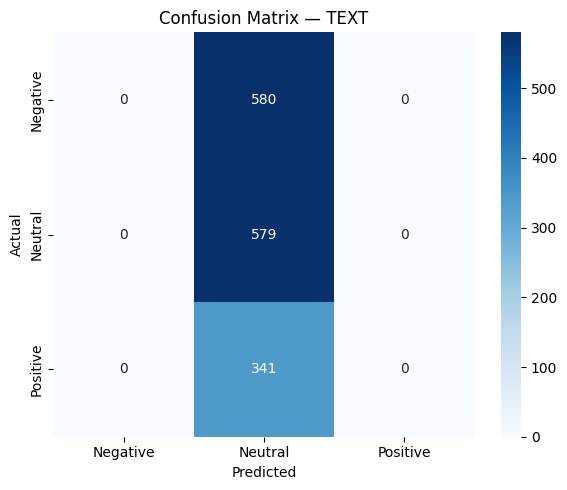

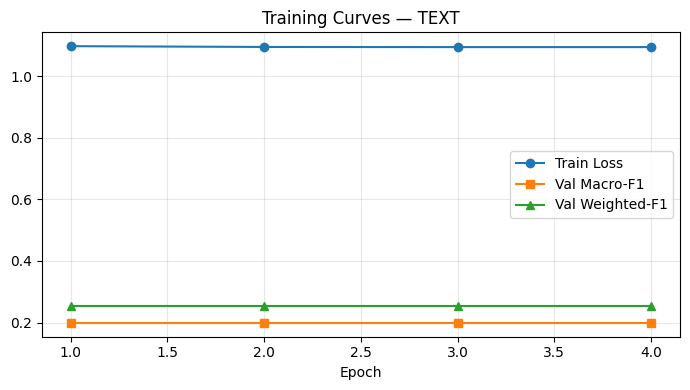


🚀 Training IMAGE | epochs=6 | batch=16x2 (eff=32) | lr_backbone=2e-05 | no encoder freeze


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (8 outputs left out)

[image] Epoch 5/6:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 5: loss=0.8290 | val_acc=0.4057 | val_macro_f1=0.3845 | val_weighted_f1=0.3997
  💾 New best Macro-F1 (0.3845) -> saved /content/drive/MyDrive/IndicSent-M_Final/best_image.pt


[image] Epoch 6/6:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 6: loss=0.7906 | val_acc=0.4000 | val_macro_f1=0.3802 | val_weighted_f1=0.3949

📊 TEST REPORT — IMAGE
              precision    recall  f1-score   support

    Negative     0.3386    0.1103    0.1664       580
     Neutral     0.3948    0.5509    0.4600       579
    Positive     0.2505    0.3695    0.2986       341

    accuracy                         0.3393      1500
   macro avg     0.3280    0.3436    0.3083      1500
weighted avg     0.3403    0.3393    0.3098      1500



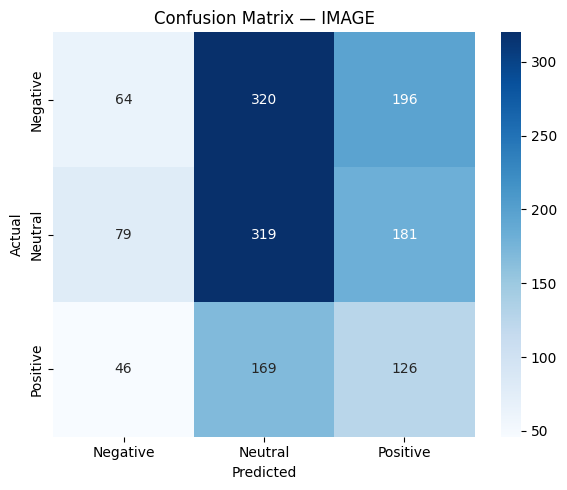

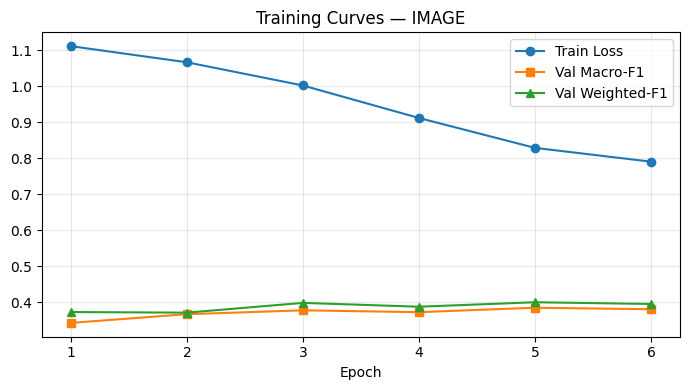


🚀 Training MULTIMODAL | epochs=6 | batch=8x4 (eff=32) | lr_backbone=2e-05 | no encoder freeze


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[multimodal] Epoch 1/6:   0%|          | 0/744 [00:00<?, ?it/s]

... (7 outputs left out)

[multimodal] Epoch 5/6:   0%|          | 0/744 [00:00<?, ?it/s]

Epoch 5: loss=0.5734 | val_acc=0.4143 | val_macro_f1=0.3950 | val_weighted_f1=0.4092
  💾 New best Macro-F1 (0.3950) -> saved /content/drive/MyDrive/IndicSent-M_Final/best_multimodal.pt


[multimodal] Epoch 6/6:   0%|          | 0/744 [00:00<?, ?it/s]

Epoch 6: loss=0.4935 | val_acc=0.4152 | val_macro_f1=0.3959 | val_weighted_f1=0.4103
  💾 New best Macro-F1 (0.3959) -> saved /content/drive/MyDrive/IndicSent-M_Final/best_multimodal.pt

📊 TEST REPORT — MULTIMODAL
              precision    recall  f1-score   support

    Negative     0.3600    0.1086    0.1669       580
     Neutral     0.3718    0.5458    0.4423       579
    Positive     0.2126    0.2962    0.2475       341

    accuracy                         0.3200      1500
   macro avg     0.3148    0.3169    0.2856      1500
weighted avg     0.3310    0.3200    0.2915      1500



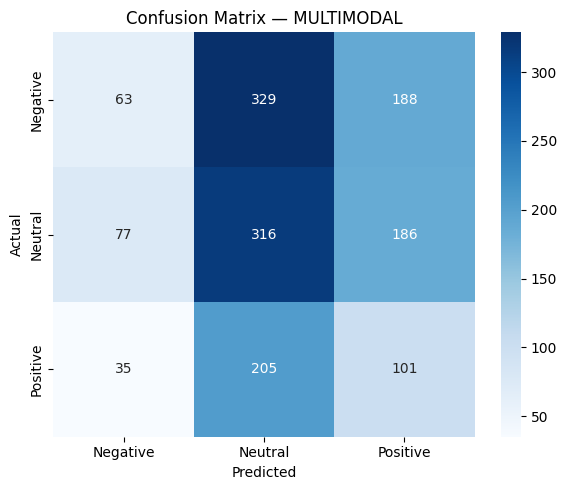

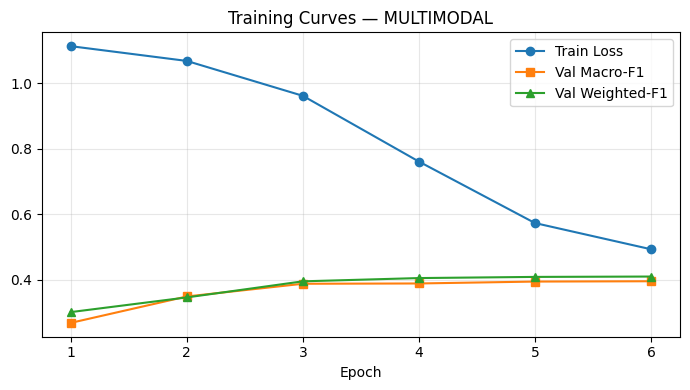

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,TEXT,0.3860,0.1287,0.3333,0.1857,0.2150
1,IMAGE,0.3393,0.3280,0.3436,0.3083,0.3098
2,MULTIMODAL,0.3200,0.3148,0.3169,0.2856,0.2915



✅ All checkpoints, tokenizer, training_config.json, plots & CSVs saved in: /content/drive/MyDrive/IndicSent-M_Final
🔎 Multimodal fixed 164 test memes where Text-only failed (ready for Grad-CAM + Captum XAI).


In [7]:
def train_model(mode):
    seed_everything(SEED)
    cfg = CONFIG["modes"][mode]
    epochs     = cfg["epochs"]
    batch_size = cfg["batch_size"]
    grad_accum = cfg["grad_accum"]

    train_loader, val_loader, test_loader = build_loaders(batch_size)
    num_batches = len(train_loader)

    print(
        f"\n{'='*65}\n"
        f"🚀 Training {mode.upper()} | epochs={epochs} | batch={batch_size}x{grad_accum} (eff={batch_size*grad_accum}) "
        f"| lr_backbone={cfg['lr_backbone']} | no encoder freeze\n"
        f"{'='*65}"
    )

    model = IndicSentModel(mode=mode, dropout=CONFIG["dropout"]).to(DEVICE)

    backbone_params = [p for n, p in model.named_parameters() if "encoder" in n]
    head_params     = [p for n, p in model.named_parameters() if "encoder" not in n]

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": cfg["lr_backbone"]},
        {"params": head_params,     "lr": cfg["lr_head"]},
    ], weight_decay=CONFIG["weight_decay"])

    updates_per_epoch = int(np.ceil(num_batches / grad_accum))
    total_steps = updates_per_epoch * epochs
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
    )

    criterion = nn.CrossEntropyLoss(
        weight=CLASS_WEIGHTS, label_smoothing=CONFIG["label_smoothing"]
    )
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_macro_f1 = -1.0
    patience_count = 0
    history = {"train_loss": [], "val_macro_f1": [], "val_weighted_f1": []}
    checkpoint = f"{SAVE_DIR}/best_{mode}.pt"

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss = 0.0

        progress = tqdm(enumerate(train_loader), total=num_batches, desc=f"[{mode}] Epoch {epoch}/{epochs}")
        for step, batch in progress:
            ids    = batch["input_ids"].to(DEVICE)
            mask   = batch["attention_mask"].to(DEVICE)
            pixels = batch["pixel_values"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            # Exact scaling for the last incomplete accumulation window
            window_start = (step // grad_accum) * grad_accum
            accum_steps  = min(grad_accum, num_batches - window_start)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits   = model(ids, mask, pixels)
                raw_loss = criterion(logits, labels)
                loss     = raw_loss / accum_steps

            scaler.scale(loss).backward()
            total_loss += raw_loss.item()

            is_update_step = ((step + 1) % grad_accum == 0) or ((step + 1) == num_batches)
            if is_update_step:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            progress.set_postfix(loss=f"{total_loss / (step + 1):.4f}")

        val_result = evaluate(model, val_loader)
        epoch_loss = total_loss / num_batches
        history["train_loss"].append(epoch_loss)
        history["val_macro_f1"].append(val_result["macro_f1"])
        history["val_weighted_f1"].append(val_result["weighted_f1"])

        print(
            f"Epoch {epoch}: loss={epoch_loss:.4f} | "
            f"val_acc={val_result['accuracy']:.4f} | "
            f"val_macro_f1={val_result['macro_f1']:.4f} | "
            f"val_weighted_f1={val_result['weighted_f1']:.4f}"
        )

        if val_result["macro_f1"] > best_macro_f1:
            best_macro_f1 = val_result["macro_f1"]
            patience_count = 0
            torch.save(model.state_dict(), checkpoint)
            print(f"  💾 New best Macro-F1 ({best_macro_f1:.4f}) -> saved {checkpoint}")
        else:
            patience_count += 1
            if patience_count >= CONFIG["patience"]:
                print(f"  ⏹️ Early stopping triggered (no Macro-F1 gain for {CONFIG['patience']} epochs).")
                break

    # Final evaluation on held-out Test Set using best checkpoint
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    test_result = evaluate(model, test_loader)

    print(f"\n📊 TEST REPORT — {mode.upper()}")
    print(classification_report(
        test_result["targets"], test_result["preds"],
        labels=[0, 1, 2], target_names=CLASS_NAMES,
        digits=4, zero_division=0
    ))

    # Save per-meme predictions + class probabilities
    pred_df = test_df.copy()
    pred_df[f"pred_{mode}"]     = test_result["preds"]
    pred_df[f"prob_neg_{mode}"] = test_result["probs"][:, 0].round(4)
    pred_df[f"prob_neu_{mode}"] = test_result["probs"][:, 1].round(4)
    pred_df[f"prob_pos_{mode}"] = test_result["probs"][:, 2].round(4)
    pred_df.to_csv(f"{SAVE_DIR}/test_preds_{mode}.csv", index=False)

    # Confusion Matrix
    cm = confusion_matrix(test_result["targets"], test_result["preds"], labels=[0, 1, 2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {mode.upper()}")
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/cm_{mode}.png", dpi=200)
    plt.show()

    # Training Curves
    ep_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(ep_range, history["train_loss"], marker="o", label="Train Loss")
    plt.plot(ep_range, history["val_macro_f1"], marker="s", label="Val Macro-F1")
    plt.plot(ep_range, history["val_weighted_f1"], marker="^", label="Val Weighted-F1")
    plt.xlabel("Epoch")
    plt.title(f"Training Curves — {mode.upper()}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/history_{mode}.png", dpi=200)
    plt.show()

    del model, optimizer, scheduler, scaler, train_loader, val_loader, test_loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return test_result, history

results = {}
histories = {}

for model_mode in ["text", "image", "multimodal"]:
    results[model_mode], histories[model_mode] = train_model(model_mode)

# Final Comparison Table
comparison = pd.DataFrame([
    {
        "Model": mode.upper(),
        "Accuracy": results[mode]["accuracy"],
        "Macro Precision": results[mode]["precision"],
        "Macro Recall": results[mode]["recall"],
        "Macro F1": results[mode]["macro_f1"],
        "Weighted F1": results[mode]["weighted_f1"]
    }
    for mode in results
])
comparison.to_csv(f"{SAVE_DIR}/comparison_results.csv", index=False)
display(comparison.round(4))

# Combined predictions CSV for qualitative sarcasm & XAI analysis
merged_preds = test_df.copy()
for mode in ["text", "image", "multimodal"]:
    merged_preds[f"pred_{mode}"]     = results[mode]["preds"]
    merged_preds[f"prob_neg_{mode}"] = results[mode]["probs"][:, 0].round(4)
    merged_preds[f"prob_neu_{mode}"] = results[mode]["probs"][:, 1].round(4)
    merged_preds[f"prob_pos_{mode}"] = results[mode]["probs"][:, 2].round(4)
merged_preds.to_csv(f"{SAVE_DIR}/test_preds_all.csv", index=False)

mm_wins = merged_preds[(merged_preds["pred_multimodal"] == merged_preds["label"]) & (merged_preds["pred_text"] != merged_preds["label"])]
print(f"\n✅ All checkpoints, tokenizer, training_config.json, plots & CSVs saved in: {SAVE_DIR}")
print(f"🔎 Multimodal fixed {len(mm_wins)} test memes where Text-only failed (ready for Grad-CAM + Captum XAI).")

## Saved Artifacts in Google Drive (`IndicSent-M_Final`)

- **Model weights:** `best_text.pt`, `best_image.pt`, `best_multimodal.pt`
- **Reproducibility:** `tokenizer/`, `training_config.json`, `train_clean.csv`, `val_clean.csv`, `test_clean.csv`
- **Evaluation:** `comparison_results.csv`, `cm_*.png`, `history_*.png`
- **XAI & Error Analysis:** `test_preds_text.csv`, `test_preds_image.csv`, `test_preds_multimodal.csv`, `test_preds_all.csv` (includes per-class confidence probabilities)

Text full balanced weights [Neg, Neu, Pos]: [1.329 0.786 1.026]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[text-fix] Epoch 1/8:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 1: loss=1.0978 | val_acc=0.2552 | val_macro_f1=0.1439 | val_pred_counts={np.int64(0): 1039, np.int64(1): 11}
  💾 Saved new best text checkpoint (Macro-F1=0.1439)


[text-fix] Epoch 2/8:   0%|          | 0/372 [00:00<?, ?it/s]

... (9 outputs left out)

[text-fix] Epoch 7/8:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 7: loss=0.7839 | val_acc=0.4171 | val_macro_f1=0.4152 | val_pred_counts={np.int64(0): 328, np.int64(1): 270, np.int64(2): 452}


[text-fix] Epoch 8/8:   0%|          | 0/372 [00:00<?, ?it/s]

Epoch 8: loss=0.7628 | val_acc=0.4086 | val_macro_f1=0.4058 | val_pred_counts={np.int64(0): 303, np.int64(1): 269, np.int64(2): 478}

📊 FIXED TEST REPORT — TEXT
              precision    recall  f1-score   support

    Negative     0.3812    0.2241    0.2823       580
     Neutral     0.3736    0.3368    0.3542       579
    Positive     0.2245    0.4194    0.2924       341

    accuracy                         0.3120      1500
   macro avg     0.3264    0.3268    0.3097      1500
weighted avg     0.3426    0.3120    0.3124      1500



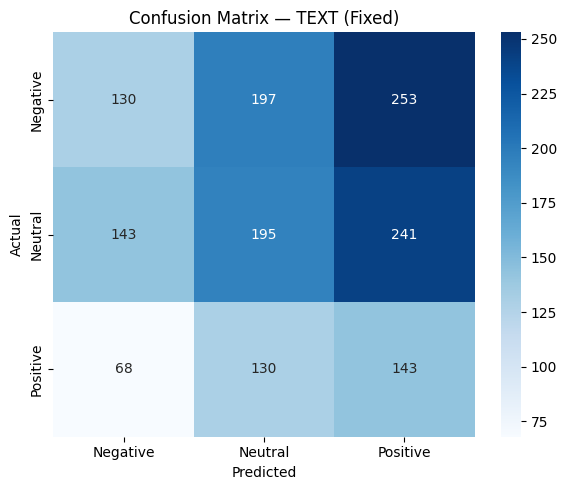

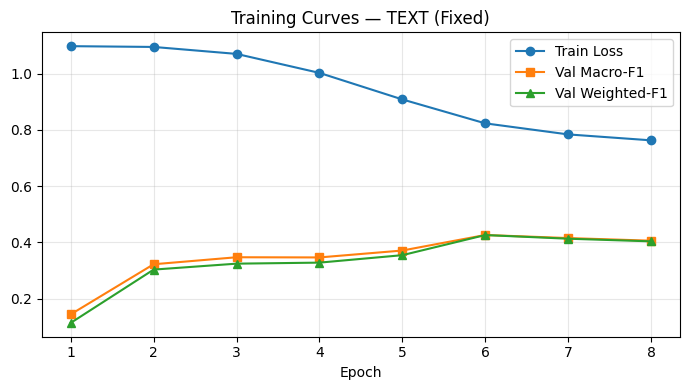

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,TEXT,0.3120,0.3264,0.3268,0.3097,0.3124
1,IMAGE,0.3393,0.3280,0.3436,0.3083,0.3098
2,MULTIMODAL,0.3200,0.3148,0.3169,0.2856,0.2915


In [8]:
from collections import Counter

def retrain_text_only(epochs=8, lr_backbone=3e-5, lr_head=2e-4, dropout=0.2, patience=4):
    seed_everything(SEED)
    train_loader, val_loader, test_loader = build_loaders(batch_size=16)
    num_batches, grad_accum = len(train_loader), 2

    # Full balanced weights penalize all-Neutral collapse (no label smoothing for text)
    full_w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_df["label"].values)
    text_weights = torch.tensor(full_w, dtype=torch.float, device=DEVICE)
    print("Text full balanced weights [Neg, Neu, Pos]:", text_weights.cpu().numpy().round(3))

    model = IndicSentModel(mode="text", dropout=dropout).to(DEVICE)
    backbone_params = [p for n, p in model.named_parameters() if "encoder" in n]
    head_params     = [p for n, p in model.named_parameters() if "encoder" not in n]

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": lr_backbone},
        {"params": head_params,     "lr": lr_head},
    ], weight_decay=0.01)

    total_steps = int(np.ceil(num_batches / grad_accum)) * epochs
    scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    criterion = nn.CrossEntropyLoss(weight=text_weights)
    scaler    = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_f1, patience_count = -1.0, 0
    history = {"train_loss": [], "val_macro_f1": [], "val_weighted_f1": []}
    checkpoint = f"{SAVE_DIR}/best_text.pt"

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss = 0.0

        progress = tqdm(enumerate(train_loader), total=num_batches, desc=f"[text-fix] Epoch {epoch}/{epochs}")
        for step, batch in progress:
            ids    = batch["input_ids"].to(DEVICE)
            mask   = batch["attention_mask"].to(DEVICE)
            pixels = batch["pixel_values"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            window_start = (step // grad_accum) * grad_accum
            accum_steps  = min(grad_accum, num_batches - window_start)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits   = model(ids, mask, pixels)
                raw_loss = criterion(logits, labels)
                loss     = raw_loss / accum_steps

            scaler.scale(loss).backward()
            total_loss += raw_loss.item()

            if ((step + 1) % grad_accum == 0) or ((step + 1) == num_batches):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            progress.set_postfix(loss=f"{total_loss / (step + 1):.4f}")

        val_res = evaluate(model, val_loader)
        ep_loss = total_loss / num_batches
        history["train_loss"].append(ep_loss)
        history["val_macro_f1"].append(val_res["macro_f1"])
        history["val_weighted_f1"].append(val_res["weighted_f1"])

        pred_dist = dict(sorted(Counter(val_res["preds"]).items()))
        print(
            f"Epoch {epoch}: loss={ep_loss:.4f} | val_acc={val_res['accuracy']:.4f} | "
            f"val_macro_f1={val_res['macro_f1']:.4f} | val_pred_counts={pred_dist}"
        )

        if val_res["macro_f1"] > best_f1:
            best_f1, patience_count = val_res["macro_f1"], 0
            torch.save(model.state_dict(), checkpoint)
            print(f"  💾 Saved new best text checkpoint (Macro-F1={best_f1:.4f})")
        else:
            patience_count += 1
            if patience_count >= patience:
                print("  ⏹️ Early stopping triggered.")
                break

    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    test_res = evaluate(model, test_loader)

    print("\n📊 FIXED TEST REPORT — TEXT")
    print(classification_report(test_res["targets"], test_res["preds"], labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0))

    # Overwrite text predictions, confusion matrix, and training curves
    pred_df = test_df.copy()
    pred_df["pred_text"]     = test_res["preds"]
    pred_df["prob_neg_text"] = test_res["probs"][:, 0].round(4)
    pred_df["prob_neu_text"] = test_res["probs"][:, 1].round(4)
    pred_df["prob_pos_text"] = test_res["probs"][:, 2].round(4)
    pred_df.to_csv(f"{SAVE_DIR}/test_preds_text.csv", index=False)

    cm = confusion_matrix(test_res["targets"], test_res["preds"], labels=[0, 1, 2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix — TEXT (Fixed)")
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/cm_text.png", dpi=200); plt.show()

    ep_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(ep_range, history["train_loss"], marker="o", label="Train Loss")
    plt.plot(ep_range, history["val_macro_f1"], marker="s", label="Val Macro-F1")
    plt.plot(ep_range, history["val_weighted_f1"], marker="^", label="Val Weighted-F1")
    plt.xlabel("Epoch"); plt.title("Training Curves — TEXT (Fixed)"); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/history_text.png", dpi=200); plt.show()

    # Update results & refresh comparison_results.csv + test_preds_all.csv
    results["text"] = test_res
    comparison = pd.DataFrame([
        {
            "Model": m.upper(),
            "Accuracy": results[m]["accuracy"],
            "Macro Precision": results[m]["precision"],
            "Macro Recall": results[m]["recall"],
            "Macro F1": results[m]["macro_f1"],
            "Weighted F1": results[m]["weighted_f1"],
        }
        for m in ["text", "image", "multimodal"] if m in results
    ])
    comparison.to_csv(f"{SAVE_DIR}/comparison_results.csv", index=False)
    display(comparison.round(4))

    merged_preds = test_df.copy()
    for m in ["text", "image", "multimodal"]:
        if m in results:
            merged_preds[f"pred_{m}"]     = results[m]["preds"]
            merged_preds[f"prob_neg_{m}"] = results[m]["probs"][:, 0].round(4)
            merged_preds[f"prob_neu_{m}"] = results[m]["probs"][:, 1].round(4)
            merged_preds[f"prob_pos_{m}"] = results[m]["probs"][:, 2].round(4)
    merged_preds.to_csv(f"{SAVE_DIR}/test_preds_all.csv", index=False)

    del model, optimizer, scheduler, scaler
    gc.collect(); torch.cuda.empty_cache()

retrain_text_only()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Warm-started encoders from best_text.pt and best_image.pt


[MM-Stage1-Head] Ep 1/2:   0%|          | 0/744 [00:00<?, ?it/s]

... (12 outputs left out)

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



📊 ABLATION TEST REPORT — LATE FUSION (alpha_text=0.55, Val Macro-F1=0.4260)
              precision    recall  f1-score   support

    Negative     0.3885    0.1862    0.2517       580
     Neutral     0.3885    0.4542    0.4188       579
    Positive     0.2459    0.3930    0.3025       341

    accuracy                         0.3367      1500
   macro avg     0.3409    0.3445    0.3243      1500
weighted avg     0.3561    0.3367    0.3278      1500



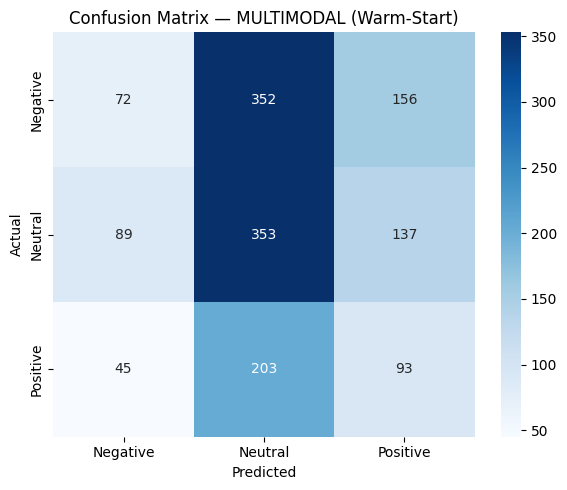

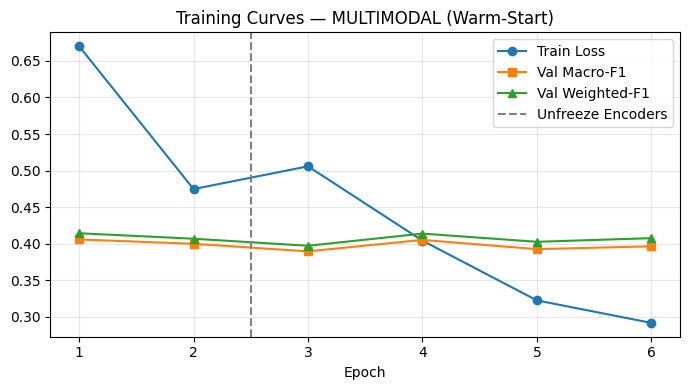

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,TEXT (MuRIL),0.3120,0.3264,0.3268,0.3097,0.3124
1,IMAGE (ViT),0.3393,0.3280,0.3436,0.3083,0.3098
2,MULTIMODAL (Gated Fusion),0.3453,0.3264,0.3355,0.3046,0.3123
3,"MULTIMODAL (Late Fusion, a=0.55)",0.3367,0.3409,0.3445,0.3243,0.3278


In [9]:
import copy
from collections import Counter

class WarmMultimodalModel(IndicSentModel):
    """Identical state_dict to IndicSentModel('multimodal'), adds modality dropout during training."""
    def __init__(self, num_classes=3, dropout=0.25, mod_drop_p=0.15):
        super().__init__(mode="multimodal", num_classes=num_classes, dropout=dropout)
        self.mod_drop_p = mod_drop_p

    def forward(self, input_ids, attention_mask, pixel_values):
        t = self.text_proj(self.encode_text(input_ids, attention_mask))
        v = self.image_proj(self.encode_image(pixel_values))

        # Modality dropout prevents ViT or MuRIL from dominating the gate
        if self.training and self.mod_drop_p > 0:
            r = torch.rand(t.size(0), 1, device=t.device)
            drop_t = (r < self.mod_drop_p).float()
            drop_v = ((r >= self.mod_drop_p) & (r < 2 * self.mod_drop_p)).float()
            t = t * (1.0 - drop_t)
            v = v * (1.0 - drop_v)

        gate = self.gate(torch.cat([t, v], dim=-1))
        fused = torch.cat([gate * t + (1.0 - gate) * v, t, v, torch.abs(t - v)], dim=-1)
        return self.classifier(fused)

def load_encoder_weights(mm_model, text_ckpt, image_ckpt):
    t_sd = torch.load(text_ckpt, map_location="cpu")
    i_sd = torch.load(image_ckpt, map_location="cpu")
    t_enc = {k.replace("text_encoder.", "", 1): v for k, v in t_sd.items() if k.startswith("text_encoder.")}
    i_enc = {k.replace("image_encoder.", "", 1): v for k, v in i_sd.items() if k.startswith("image_encoder.")}
    mm_model.text_encoder.load_state_dict(t_enc, strict=True)
    mm_model.image_encoder.load_state_dict(i_enc, strict=True)
    print(f"✅ Warm-started encoders from {os.path.basename(text_ckpt)} and {os.path.basename(image_ckpt)}")

def retrain_multimodal_warmstart(stage1_epochs=2, stage2_epochs=4):
    seed_everything(SEED)
    train_loader, val_loader, test_loader = build_loaders(batch_size=8)
    num_batches, grad_accum = len(train_loader), 4

    # Same full balanced weights as Fixed Text for a fair comparison & strong Negative recall
    full_w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_df["label"].values)
    bal_weights = torch.tensor(full_w, dtype=torch.float, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=bal_weights)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    model = WarmMultimodalModel(dropout=0.25, mod_drop_p=0.15).to(DEVICE)
    load_encoder_weights(model, f"{SAVE_DIR}/best_text.pt", f"{SAVE_DIR}/best_image.pt")

    best_f1 = -1.0
    history = {"train_loss": [], "val_macro_f1": [], "val_weighted_f1": []}
    checkpoint = f"{SAVE_DIR}/best_multimodal.pt"
    total_epochs = stage1_epochs + stage2_epochs

    def run_stage(stage_name, n_epochs, optimizer, freeze_encoders):
        nonlocal best_f1
        for name, p in model.named_parameters():
            if "encoder" in name:
                p.requires_grad = not freeze_encoders

        updates = int(np.ceil(num_batches / grad_accum)) * n_epochs
        scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.1 * updates), updates)

        for ep in range(1, n_epochs + 1):
            model.train()
            # Keep frozen encoders in eval mode during Stage 1 so their dropout stays off
            if freeze_encoders:
                model.text_encoder.eval()
                model.image_encoder.eval()

            optimizer.zero_grad(set_to_none=True)
            total_loss = 0.0
            pbar = tqdm(enumerate(train_loader), total=num_batches, desc=f"[MM-{stage_name}] Ep {ep}/{n_epochs}")
            for step, batch in pbar:
                ids    = batch["input_ids"].to(DEVICE)
                mask   = batch["attention_mask"].to(DEVICE)
                pixels = batch["pixel_values"].to(DEVICE)
                labels = batch["label"].to(DEVICE)

                window_start = (step // grad_accum) * grad_accum
                accum_steps  = min(grad_accum, num_batches - window_start)

                with torch.amp.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                    logits   = model(ids, mask, pixels)
                    raw_loss = criterion(logits, labels)
                    loss     = raw_loss / accum_steps

                scaler.scale(loss).backward()
                total_loss += raw_loss.item()

                if ((step + 1) % grad_accum == 0) or ((step + 1) == num_batches):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    scheduler.step()

                pbar.set_postfix(loss=f"{total_loss / (step + 1):.4f}")

            val_res = evaluate(model, val_loader)
            ep_loss = total_loss / num_batches
            history["train_loss"].append(ep_loss)
            history["val_macro_f1"].append(val_res["macro_f1"])
            history["val_weighted_f1"].append(val_res["weighted_f1"])

            pred_dist = dict(sorted(Counter(val_res["preds"]).items()))
            print(
                f"[{stage_name} Ep {ep}] loss={ep_loss:.4f} | val_acc={val_res['accuracy']:.4f} | "
                f"val_macro_f1={val_res['macro_f1']:.4f} | preds={pred_dist}"
            )

            if val_res["macro_f1"] > best_f1:
                best_f1 = val_res["macro_f1"]
                torch.save(model.state_dict(), checkpoint)
                print(f"  💾 Saved new best multimodal checkpoint (Val Macro-F1={best_f1:.4f})")

    # Stage 1: Align fusion gate & classifier head with frozen encoders
    head_params = [p for n, p in model.named_parameters() if "encoder" not in n]
    opt_s1 = torch.optim.AdamW(head_params, lr=3e-4, weight_decay=0.02)
    run_stage("Stage1-Head", stage1_epochs, opt_s1, freeze_encoders=True)

    # Stage 2: Reload best Stage-1 weights & gently fine-tune jointly
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    opt_s2 = torch.optim.AdamW([
        {"params": model.text_encoder.parameters(),  "lr": 1e-5},
        {"params": model.image_encoder.parameters(), "lr": 5e-6},
        {"params": head_params,                      "lr": 5e-5},
    ], weight_decay=0.02)
    run_stage("Stage2-Joint", stage2_epochs, opt_s2, freeze_encoders=False)

    # Evaluate Best Warm-Started Multimodal on Test Set
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
    test_res = evaluate(model, test_loader)
    print("\n📊 FIXED TEST REPORT — MULTIMODAL (WARM-START GATED FUSION)")
    print(classification_report(test_res["targets"], test_res["preds"], labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0))

    # --- Bonus Ablation: Late Fusion Ensemble (blend weight tuned strictly on Val) ---
    t_model = IndicSentModel(mode="text", dropout=0.2).to(DEVICE)
    t_model.load_state_dict(torch.load(f"{SAVE_DIR}/best_text.pt", map_location=DEVICE))
    i_model = IndicSentModel(mode="image", dropout=0.4).to(DEVICE)
    i_model.load_state_dict(torch.load(f"{SAVE_DIR}/best_image.pt", map_location=DEVICE))

    t_val, i_val   = evaluate(t_model, val_loader),  evaluate(i_model, val_loader)
    t_test, i_test = evaluate(t_model, test_loader), evaluate(i_model, test_loader)

    best_alpha, best_lf_val = 0.5, -1.0
    for alpha in np.linspace(0.1, 0.9, 17):
        blend_val = alpha * t_val["probs"] + (1 - alpha) * i_val["probs"]
        _, _, mf1, _ = precision_recall_fscore_support(t_val["targets"], blend_val.argmax(1), average="macro", zero_division=0)
        if mf1 > best_lf_val:
            best_lf_val, best_alpha = mf1, alpha

    blend_test = best_alpha * t_test["probs"] + (1 - best_alpha) * i_test["probs"]
    lf_preds = blend_test.argmax(1)
    lf_p, lf_r, lf_mf1, _ = precision_recall_fscore_support(t_test["targets"], lf_preds, average="macro", zero_division=0)
    _, _, lf_wf1, _       = precision_recall_fscore_support(t_test["targets"], lf_preds, average="weighted", zero_division=0)
    lf_res = {
        "accuracy": accuracy_score(t_test["targets"], lf_preds),
        "precision": lf_p, "recall": lf_r, "macro_f1": lf_mf1, "weighted_f1": lf_wf1,
        "preds": lf_preds, "targets": t_test["targets"], "probs": blend_test,
    }
    print(f"\n📊 ABLATION TEST REPORT — LATE FUSION (alpha_text={best_alpha:.2f}, Val Macro-F1={best_lf_val:.4f})")
    print(classification_report(lf_res["targets"], lf_res["preds"], labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0))

    # Save updated multimodal predictions, confusion matrix, training curves & comparison CSV
    pred_df = test_df.copy()
    pred_df["pred_multimodal"]     = test_res["preds"]
    pred_df["prob_neg_multimodal"] = test_res["probs"][:, 0].round(4)
    pred_df["prob_neu_multimodal"] = test_res["probs"][:, 1].round(4)
    pred_df["prob_pos_multimodal"] = test_res["probs"][:, 2].round(4)
    pred_df.to_csv(f"{SAVE_DIR}/test_preds_multimodal.csv", index=False)

    cm = confusion_matrix(test_res["targets"], test_res["preds"], labels=[0, 1, 2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix — MULTIMODAL (Warm-Start)")
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/cm_multimodal.png", dpi=200); plt.show()

    ep_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(ep_range, history["train_loss"], marker="o", label="Train Loss")
    plt.plot(ep_range, history["val_macro_f1"], marker="s", label="Val Macro-F1")
    plt.plot(ep_range, history["val_weighted_f1"], marker="^", label="Val Weighted-F1")
    plt.axvline(stage1_epochs + 0.5, color="gray", linestyle="--", label="Unfreeze Encoders")
    plt.xlabel("Epoch"); plt.title("Training Curves — MULTIMODAL (Warm-Start)"); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/history_multimodal.png", dpi=200); plt.show()

    results["text"], results["image"], results["multimodal"], results["late_fusion"] = t_test, i_test, test_res, lf_res
    comparison = pd.DataFrame([
        {
            "Model": name,
            "Accuracy": res["accuracy"],
            "Macro Precision": res["precision"],
            "Macro Recall": res["recall"],
            "Macro F1": res["macro_f1"],
            "Weighted F1": res["weighted_f1"],
        }
        for name, res in [
            ("TEXT (MuRIL)", t_test),
            ("IMAGE (ViT)", i_test),
            ("MULTIMODAL (Gated Fusion)", test_res),
            (f"MULTIMODAL (Late Fusion, a={best_alpha:.2f})", lf_res),
        ]
    ])
    comparison.to_csv(f"{SAVE_DIR}/comparison_results.csv", index=False)
    display(comparison.round(4))

    merged_preds = test_df.copy()
    for m in ["text", "image", "multimodal"]:
        merged_preds[f"pred_{m}"]     = results[m]["preds"]
        merged_preds[f"prob_neg_{m}"] = results[m]["probs"][:, 0].round(4)
        merged_preds[f"prob_neu_{m}"] = results[m]["probs"][:, 1].round(4)
        merged_preds[f"prob_pos_{m}"] = results[m]["probs"][:, 2].round(4)
    merged_preds.to_csv(f"{SAVE_DIR}/test_preds_all.csv", index=False)

    del model, t_model, i_model, opt_s1, opt_s2, scaler
    gc.collect(); torch.cuda.empty_cache()

retrain_multimodal_warmstart()